# Part 2 - UWB Anchor Global Localization (GDOP & Incorrect Anchor Placement)

This notebook explores UWB-based robot localization with:

- Geometric Dilution of Precision (GDOP) analysis
- UWB anchor placement evaluation
- Anchor mis-calibration effects on pose estimation

In [4]:
# Imports
import sys
sys.path.insert(0, '../src')
import part2_functions
from config import TrajectoryConfig, UWBNoiseConfig
import numpy as np


In [5]:
# Parameters

# Define 3 anchor positions in 2D (forming a roughly equilateral triangle)
anchor_positions = np.array([
    [0.0, 0.0],      # Anchor 1 at origin
    [20.0, 0.0],     # Anchor 2 on x-axis
    [10.0, 17.32]    # Anchor 3 forming equilateral triangle (height = 20 * sqrt(3)/2)
])

# Trajectory config
traj_config = TrajectoryConfig(duration=50.0, timestep=0.1, seed=42)

# UWB noise parameters
uwb_noise_config = UWBNoiseConfig(sigma_range=0.2)  # 20 cm range noise

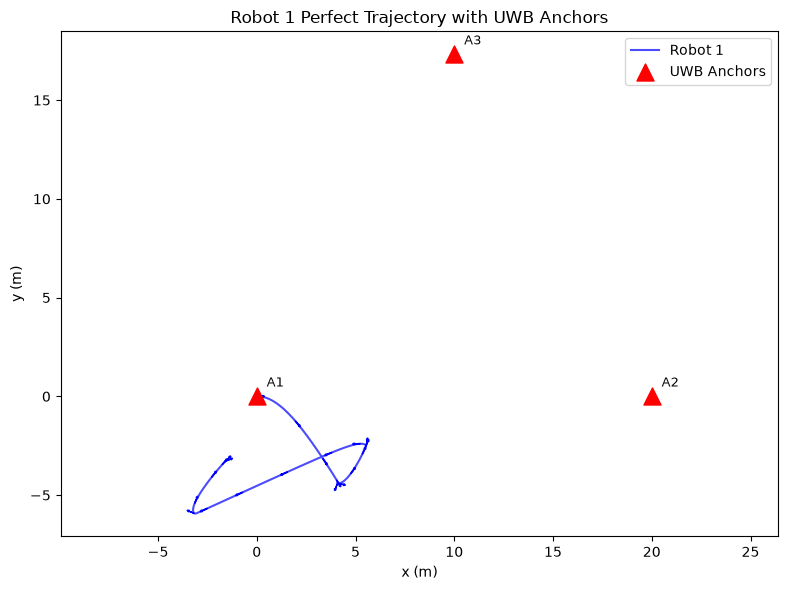

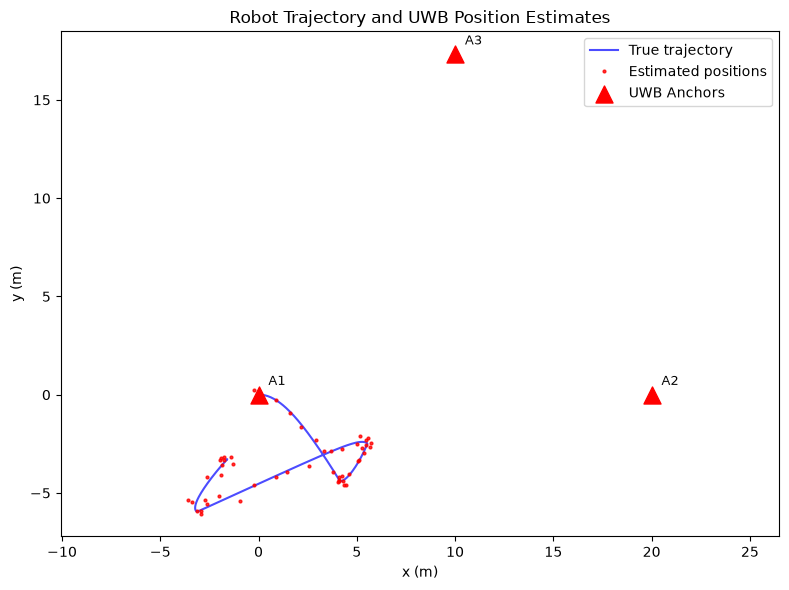

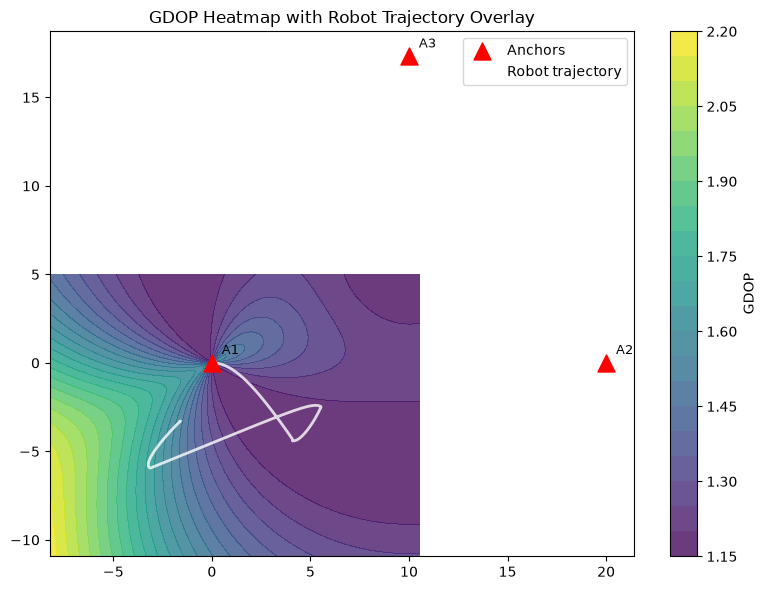

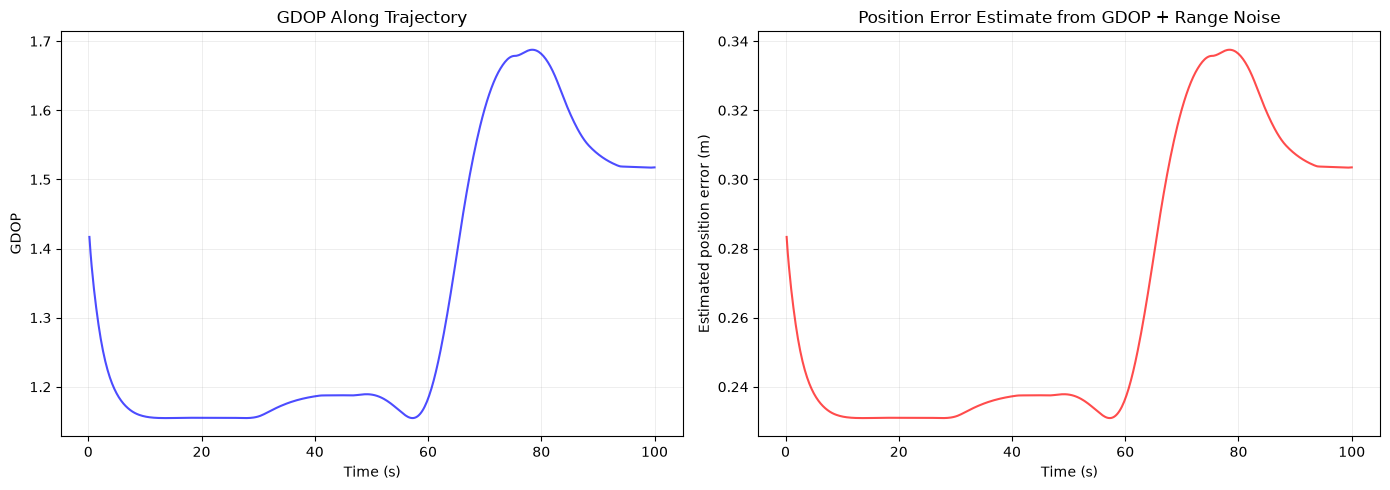

In [6]:
# Run UWB analysis

# Visualize robot trajectory with anchors
poses_robot1 = part2_functions.plot_robot_with_anchors(traj_config, anchor_positions)

# Run full UWB localization analysis
results = part2_functions.run_uwb_analysis(poses_robot1, anchor_positions, uwb_noise_config)

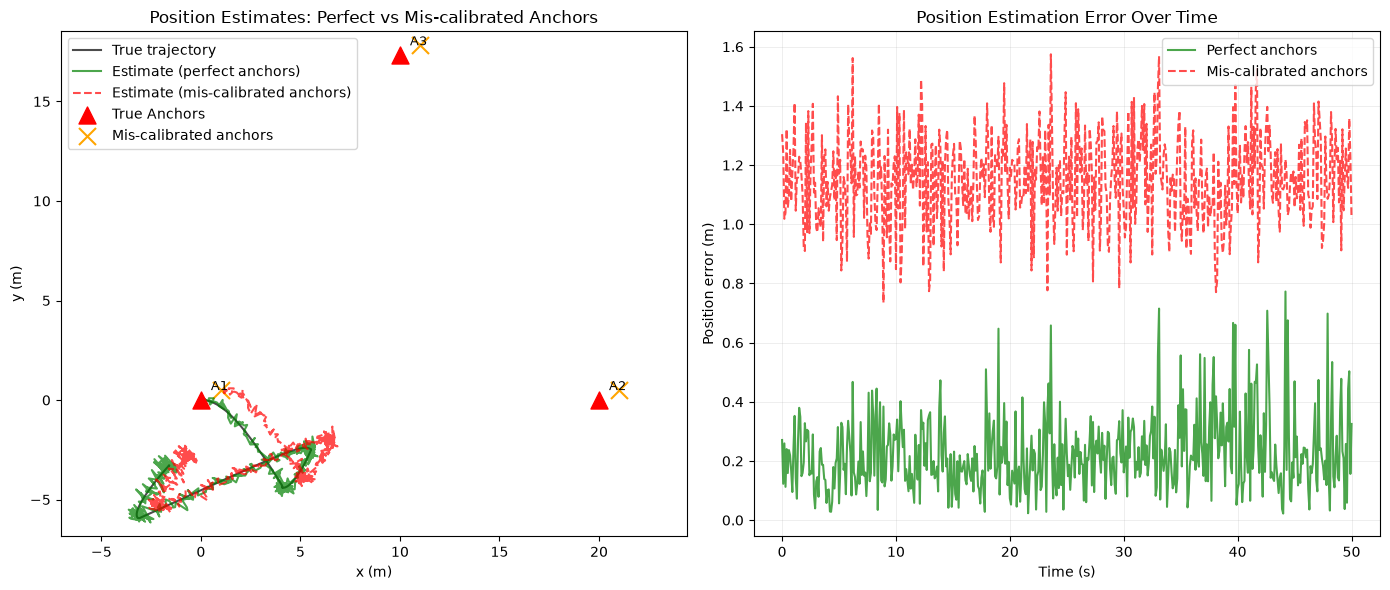

=== UWB Localization Performance ===
Perfect anchors - Final position error: 0.325 m
Perfect anchors - Mean position error: 0.224 m

Mis-calibrated anchors - Final position error: 1.019 m
Mis-calibrated anchors - Mean position error: 1.150 m

Anchor calibration bias magnitude: 1.12 m


In [7]:
# Analyze anchor mis-calibration

# Define systematic offset for anchor positions (mis-calibration)
anchor_offset = np.array([1.0, 0.5])  # [delta_x, delta_y]

# Get ranges from previous analysis
from uwb import simulate_uwb_ranges
ranges_robot1 = simulate_uwb_ranges(poses_robot1, anchor_positions, uwb_noise_config)

# Run miscalibration analysis
part2_functions.analyze_anchor_miscalibration(
    poses_robot1, 
    ranges_robot1, 
    anchor_positions, 
    anchor_offset, 
    uwb_noise_config
)

# Conclusion

## Summary of Key Findings

### 1. UWB Trilateration Performance
- From range measurements to 3 anchors, we estimated robot positions via trilateration
- Position estimates show small errors due to Gaussian range noise

### 2. GDOP Analysis
- GDOP quantifies geometry-dependent error amplification
- Lower GDOP values indicate better anchor geometry
- Heatmap shows regions where positioning accuracy is optimal/poor
- Trajectory should avoid high-GDOP regions for best accuracy

### 3. Anchor Mis-calibration Effects
- Systematic bias in anchor positions directly translates to position estimation error
- Error grows over time as the robot moves away from anchors
- Mis-calibration can dominate performance compared to range measurement noise

## Connection to Part 1

In Part 1, we saw that global pose noise propagates into relative pose estimates.

Here, we see a similar but more severe effect:
- Global pose uncertainty comes from both measurement noise (GDOP) and anchor calibration errors
- Position estimation error can be much larger than in Part 1 due to GDOP amplification
- Anchor mis-calibration creates systematic biases that accumulate across the trajectory

## Recommendations for UWB Deployment

1. **Anchor geometry**: Place anchors at ~120° angles around operating area
2. **GDOP mapping**: Use GDOP heatmaps to identify high-error regions before deployment
3. **Calibration**: Regularly calibrate anchor positions (e.g., using total station or precise RTK-GNSS)
4. **Redundancy**: Add 4th+ anchors for outlier rejection and improved geometry